(768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
Outcome
0    500
1    268
Name: count, dtype: int64
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age               

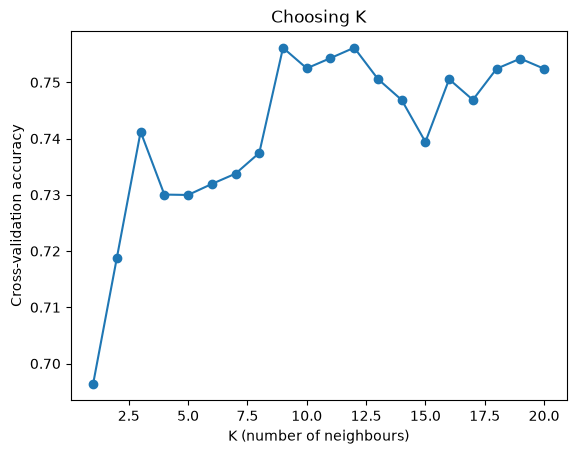

Confusion matrix:
 [[130  20]
 [ 43  38]]
TN=130  FP=20  FN=43  TP=38
Accuracy   = (TP+TN)/total = 0.7273
Error rate = (FP+FN)/total = 0.2727
Precision  = TP/(TP+FP)    = 0.6552
Recall     = TP/(TP+FN)    = 0.4691

Check with sklearn:
Accuracy : 0.7273
Error    : 0.2727
Precision: 0.6552
Recall   : 0.4691
              precision    recall  f1-score   support

 No diabetes       0.75      0.87      0.80       150
    Diabetes       0.66      0.47      0.55        81

    accuracy                           0.73       231
   macro avg       0.70      0.67      0.68       231
weighted avg       0.72      0.73      0.71       231



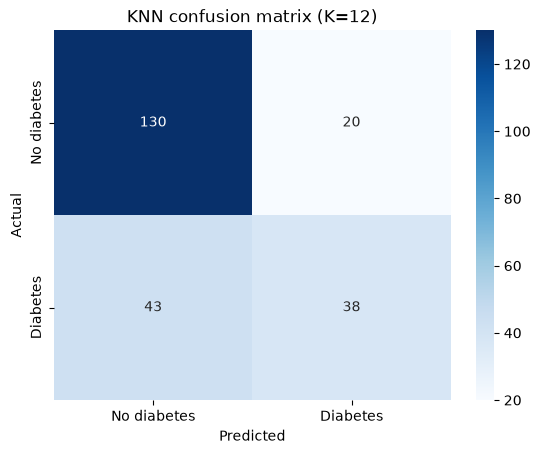

In [2]:
# =====================================================================
#  DIABETES PREDICTION  -  K-Nearest Neighbors (KNN) classifier
#  Dataset: diabetes.csv (Pima Indians Diabetes, 768 patients)
#  Task: build KNN, then compute confusion matrix, accuracy, error rate,
#        precision and recall.
#  Run in Google Colab / Jupyter (each "# %%" marks one cell)
# =====================================================================
#
# ---------------------------------------------------------------------
#  PART A: HIGH-LEVEL IDEA (read this first)
# ---------------------------------------------------------------------
# PROBLEM:
#   Each row is a patient with 8 measurements (Glucose, BMI, Age, ...).
#   The last column 'Outcome' says whether the patient has diabetes
#   (1 = diabetes, 0 = no diabetes). Two possible answers = BINARY
#   CLASSIFICATION.
#
# HOW KNN WORKS (in simple words):
#   KNN = "tell me who your K nearest neighbours are, and I will tell you who you are".
#   To classify a NEW patient:
#     1. Measure the DISTANCE from the new patient to every patient in the
#        training data (straight-line / Euclidean distance over all 8 columns).
#     2. Pick the K closest patients (the neighbours).
#     3. Take a MAJORITY VOTE of their Outcome. If most neighbours have diabetes,
#        predict diabetes; otherwise predict no diabetes.
#   There is no real "learning": KNN just remembers the training data
#   (so it is called a LAZY learner). All the work happens at prediction time.
#
#   Distance between two patients a and b (Euclidean):
#        d = sqrt( (a1-b1)^2 + (a2-b2)^2 + ... + (a8-b8)^2 )
#   Because it is distance-based, columns with BIG numbers (Insulin up to 800)
#   would dominate columns with small numbers (DiabetesPedigreeFunction ~ 0.5).
#   So we must SCALE all columns to the same range first.
#
# ---------------------------------------------------------------------
#  PART B: THE ALGORITHM (what we will do, step by step)
# ---------------------------------------------------------------------
#  1. READ the file into a table:               df = pd.read_csv(...)
#  2. FIX BAD DATA: in Glucose, BloodPressure, SkinThickness, Insulin and BMI a
#     value of 0 is impossible (nobody has 0 blood pressure) - it really means
#     "missing". We mark those zeros as missing and fill them later.
#  3. CREATE X AND y:
#        X = all 8 input columns (what KNN may look at): X = df.drop(columns=['Outcome'])
#        y = the 'Outcome' column (the answer we want to predict).
#  4. SPLIT into TRAIN (the patients KNN remembers) and TEST (new patients to classify).
#  5. FILL the missing values using the median of the TRAIN data.
#  6. SCALE all columns to mean 0 / std 1 (fit on train only).
#  7. CHOOSE K: try K = 1..20 using cross-validation on the train data, keep the best.
#  8. TRAIN KNN with that K and PREDICT the test patients.
#  9. COMPUTE the confusion matrix, accuracy, error rate, precision, recall.
# ---------------------------------------------------------------------
 
 
# %% STEP 0: IMPORT LIBRARIES
import numpy as np                        # maths on arrays; we need np.nan (the "missing" marker)
import pandas as pd                       # tables (DataFrame)
import matplotlib.pyplot as plt           # basic plots
import seaborn as sns                     # heatmap for the confusion matrix
 
from sklearn.model_selection import train_test_split, cross_val_score
# train_test_split : cuts data into train and test parts
# cross_val_score  : tests a model several times on slices of the TRAIN data (used to choose K)
from sklearn.preprocessing import StandardScaler          # scales columns to mean 0, std 1
from sklearn.neighbors import KNeighborsClassifier        # the KNN model
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             precision_score, recall_score, classification_report)
 
 
# %% STEP 1: READ THE DATASET
df = pd.read_csv('diabetes.csv')          # read the CSV file into a DataFrame called df
print(df.shape)                           # (rows, columns) -> expect (768, 9)
print(df.head())                          # first 5 rows
print(df['Outcome'].value_counts())
# .value_counts() counts each value: 0 = no diabetes (about 500), 1 = diabetes (about 268).
# The classes are not equal (imbalanced), so accuracy alone can mislead; that is
# why we also compute precision and recall.
 
 
# %% STEP 2: FIX IMPOSSIBLE ZEROS (pre-processing)
cols_with_fake_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols_with_fake_zeros] = df[cols_with_fake_zeros].replace(0, np.nan)
# df[[list of columns]] selects several columns at once.
# .replace(0, np.nan) swaps every 0 by NaN ("Not a Number" = the standard marker for a
# missing value). We do NOT do this for Pregnancies (0 pregnancies is valid) or Outcome
# (0 means no diabetes).
print(df.isnull().sum())
# .isnull() marks missing cells, .sum() counts them per column: Insulin has ~374 missing
# and SkinThickness ~227. Cleaning matters here: zeros would wrongly make patients look "close"
# to each other in the distance calculation.
 
 
# %% STEP 3: CREATE X (INPUTS) AND y (ANSWER)
X = df.drop(columns=['Outcome'])
# X = every column EXCEPT 'Outcome': Pregnancies, Glucose, BloodPressure, SkinThickness,
# Insulin, BMI, DiabetesPedigreeFunction, Age -> the 8 measurements KNN will compare.
# (If 'Outcome' stayed in X, KNN would simply read the answer.)
y = df['Outcome']
# y = only the 'Outcome' column: 1 = diabetes, 0 = no diabetes.
print("X shape:", X.shape, "| y shape:", y.shape)    # (768, 8) and (768,)
 
 
# %% STEP 4: SPLIT INTO TRAIN AND TEST
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
# test_size=0.3   -> 30% of patients are hidden for testing, 70% are the "memory" of KNN.
# random_state=42 -> same shuffle on every run (repeatable results).
# stratify=y      -> keeps the same diabetes / no-diabetes ratio in both parts.
# It returns 4 parts: train inputs, test inputs, train answers, test answers.
 
 
# %% STEP 5: FILL THE MISSING VALUES
medians = X_train.median()
# .median() = the middle value of each column, computed on the TRAIN data only.
# We use the median (not the mean) because Insulin and SkinThickness have extreme values
# that would pull the mean away from a typical patient.
X_train = X_train.fillna(medians)
# .fillna(medians) fills every NaN with the median of ITS OWN column.
X_test = X_test.fillna(medians)
# Test patients are filled with the TRAIN medians (not their own): this way no test
# information leaks into training.
print("Missing values left:", X_train.isnull().sum().sum() + X_test.isnull().sum().sum())   # 0
 
 
# %% STEP 6: SCALE THE DATA (mean 0, standard deviation 1)
scaler = StandardScaler()                     # create the scaler object
X_train = scaler.fit_transform(X_train)
# fit_transform = fit() learns each column's mean and std from TRAIN, then transform()
# applies  z = (value - mean) / std . Now every column has a similar size, so every
# measurement gets a fair say in the distance.
X_test = scaler.transform(X_test)
# transform() only: use the SAME mean/std learned from train. Never fit on test data.
 
 
# %% STEP 7: CHOOSE THE BEST K (using only the TRAIN data)
# K too small (1) = follows noise; K too large = too blurry. We test K = 1..20.
# (Odd K values avoid tied votes, but we simply test all and let the numbers decide.)
k_values = range(1, 21)
cv_scores = []
for k in k_values:
    knn_try = KNeighborsClassifier(n_neighbors=k)
    # n_neighbors = K, the number of neighbours that vote.
    score = cross_val_score(knn_try, X_train, y_train, cv=5).mean()
    # cross_val_score(model, X, y, cv=5): splits the TRAIN data into 5 parts, trains on 4
    # and tests on 1, five times, returns 5 accuracies; .mean() averages them.
    # This tests K without touching the real test set (the reference code picked K by
    # looking at test scores, which is unfair).
    cv_scores.append(score)
 
best_k = list(k_values)[int(np.argmax(cv_scores))]
# np.argmax gives the POSITION of the largest score; we use it to read the matching K.
print("Best K:", best_k, "| cross-val accuracy:", round(max(cv_scores), 4))
 
plt.plot(k_values, cv_scores, marker='o')     # marker='o' draws a dot at every point
plt.xlabel('K (number of neighbours)'); plt.ylabel('Cross-validation accuracy')
plt.title('Choosing K'); plt.show()
 
 
# %% STEP 8: TRAIN KNN AND PREDICT
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)
# fit() for KNN only STORES the training patients (lazy learner): no weights are learned.
y_pred = knn.predict(X_test)
# predict() : for every test patient, find the K nearest training patients and take the
# majority vote of their Outcome. y_pred holds one 0/1 prediction per test patient.
 
 
# %% STEP 9: CONFUSION MATRIX, ACCURACY, ERROR RATE, PRECISION, RECALL
# POSITIVE class = 1 (has diabetes).
# The CONFUSION MATRIX counts every kind of right and wrong answer:
#
#                       Predicted 0 (no diabetes) | Predicted 1 (diabetes)
#   Actual 0 (healthy)        TN                  |        FP   (false alarm)
#   Actual 1 (diabetes)       FN  (MISSED patient)|        TP
#
cm = confusion_matrix(y_test, y_pred)
# Returns [[TN, FP], [FN, TP]] as a 2 x 2 array. Order of arguments: (true, predicted).
print("Confusion matrix:\n", cm)
 
TN, FP, FN, TP = cm.ravel()
# .ravel() flattens the 2 x 2 matrix into 4 numbers in the order TN, FP, FN, TP, so we can
# name them in one line.
total = TN + FP + FN + TP
 
# --- The metrics, from the formulas ---
accuracy   = (TP + TN) / total        # share of ALL predictions that were right
error_rate = (FP + FN) / total        # share that were WRONG  (= 1 - accuracy)
precision  = TP / (TP + FP)           # of patients we called diabetic, how many really are
recall     = TP / (TP + FN)           # of all real diabetic patients, how many we caught
 
print(f"TN={TN}  FP={FP}  FN={FN}  TP={TP}")
print(f"Accuracy   = (TP+TN)/total = {accuracy:.4f}")
print(f"Error rate = (FP+FN)/total = {error_rate:.4f}")
print(f"Precision  = TP/(TP+FP)    = {precision:.4f}")
print(f"Recall     = TP/(TP+FN)    = {recall:.4f}")
# f"...{value:.4f}" is an f-string: it puts the value in the text with 4 decimals.
 
# --- Cross-check with scikit-learn's ready-made functions (must give the same numbers) ---
print("\nCheck with sklearn:")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Error    :", round(1 - accuracy_score(y_test, y_pred), 4))     # there is no error_rate function: it is 1 - accuracy
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=['No diabetes', 'Diabetes']))
# classification_report prints precision, recall, F1 and support for BOTH classes.
 
# Plot the confusion matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No diabetes', 'Diabetes'], yticklabels=['No diabetes', 'Diabetes'])
# annot=True writes the counts inside the cells; fmt='d' = whole numbers.
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(f'KNN confusion matrix (K={best_k})')
plt.show()
 
 
# %% STEP 10: CONCLUSION (write in your journal, with YOUR numbers)
# - Accuracy tells how often KNN is right overall; error rate = 1 - accuracy.
# - Precision: when KNN says "diabetes", how often is it correct?
# - Recall: how many of the real diabetic patients did KNN catch?
#   In medicine a missed patient (FN) is worse than a false alarm (FP), so recall is
#   especially important here.
# - KNN depends on scaling and on the choice of K; it is simple but slow on very large data
#   because it must compare each new patient with all stored patients.